## Handwritten digit classifier
- Train a neural network that takes 28x28 image inputs and predict 0~9 what number it is.
- Implement the neural network and backpropagation algorithm from scratch with only numpy and no other ML library.

### 1. Load and inspect the image

In [128]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt


In [129]:
seed = 42
rng = np.random.default_rng(seed)

data  = pd.read_csv('data/train.csv')
assert data.shape[1] == 785 and 'label' in data, "Expected label and 784 features in the dataset"
assert not data.isna().any().any(), "Dataset contains NaN values"
pixels = data.drop(columns='label').to_numpy(dtype = np.float64)
labels = data['label'].to_numpy(dtype = np.int64)
assert np.all((labels >= 0) & (labels <= 9)), "Labels must be in the range [0, 9]"
assert np.all((pixels >= 0) & (pixels <= 255)), "Pixel values must be in the range [0, 255]"
X = pixels / 255.0  # Normalize pixel values to [0, 1]
print(f"Loaded {len(X):,} \nExamples: X {X.shape}\nLabel {labels.shape}")

Loaded 42,000 
Examples: X (42000, 784)
Label (42000,)


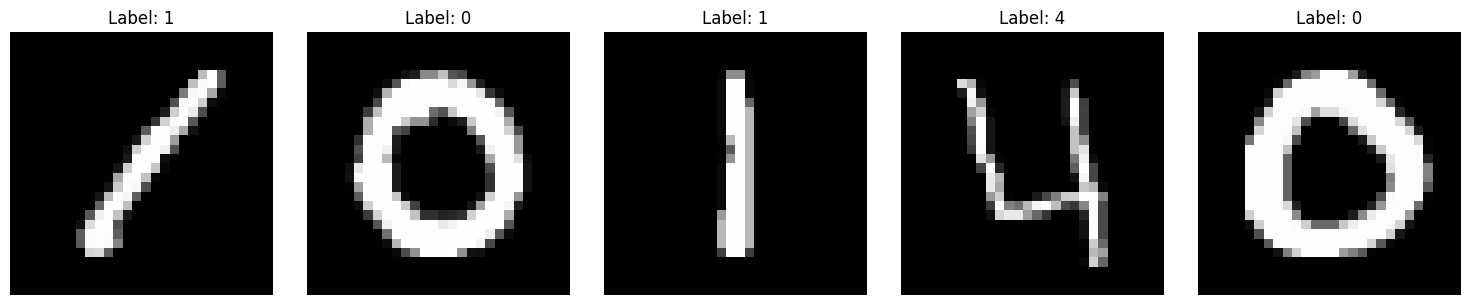

In [130]:
#show the first 5 examples
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, index in zip(axes, range(5)):
    ax.imshow(pixels[index].reshape(28, 28), cmap='gray', vmin = 0, vmax = 255)
    ax.set_title(f"Label: {labels[index]}")
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2. Auto-grad engine
- Followed the Andrej Karpathy's youtube video, but adjust to perform matrix operations

In [131]:
class Value:
    def __init__(self, data, _children=(), _op=''):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self._prev = tuple(_children)
        self._op = _op
        self._backward = lambda: None

    def __repr__(self):
        return f'Value(shape = {self.data.shape}, data = {self.data})'

    @staticmethod
    def unbroadcast(grad, shape):
        #sum the gradient back to original input's shape 
        while grad.ndim > len(shape):
            #handle sum over extra dimensions
            grad  = grad.sum(axis = 0)
        for axis, size in enumerate(shape):
            #handle sum if original dimension have size 1
            if size == 1:
                grad = grad.sum(axis = axis, keepdims = True)
        return grad

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += self.unbroadcast(out.grad, self.data.shape)
            other.grad += self.unbroadcast(out.grad, other.data.shape)

        out._backward = _backward
        return out

    __radd__ = __add__

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += self.unbroadcast(other.data * out.grad, self.data.shape)
            other.grad += self.unbroadcast(self.data * out.grad, other.data.shape)

        out._backward = _backward
        return out

    __rmul__ = __mul__

    def __matmul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        if self.data.ndim != 2 or other.data.ndim != 2:
            raise ValueError("Matrix multiplication required 2D arrays")

        out = Value(self.data @ other.data, (self, other), "@") #(a x b)x(b x c) = (a x c)
        def _backward():
            self.grad += out.grad @ other.data.T #(a x b) = (a x c)x(c x b)
            other.grad += self.data.T @ out.grad #(b x c) = (b x a)x(a x c)

        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += out.grad * (1 - t**2)

        out._backward = _backward

        return out

    def __pow__(self, power):
        if not isinstance(power, (int, float)):
            raise TypeError('Power nust be a numeric constant')

        out = Value(self.data ** power, (self, ), "**")
        def _backward():
            self.grad += out.grad * power * (self.data**(power-1))
        out._backward = _backward
        return out

    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.grad * out.data
        out._backward = _backward
        return out

    def sum(self):
        out = Value(self.data.sum(), (self,), "sum")
        def _backward():
            self.grad += np.ones_like(self.data) * out.grad
        out._backward = _backward
        return out

    def mean(self):
        if self.data.size == 0:
            raise ValueError("Cannot average an empyty array")
        return self.sum() * (1.0/self.data.size)

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other if isinstance(other, Value) else -np.asarray(other))

    def __rsub__(self, other):
        return other + (-self)

    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self * (other**-1)

    def __rtruediv__(self, other):
        return other * (self**-1)

    def backward(self):
        #call backward on each node in reverse topological order
        if self.data.ndim != 0:
            raise ValueError("Loss needs to be scalar")

        topo, visited = [], set()
        def visit(node):
            if node not in visited:
                visited.add(node)
                for parent in node._prev:
                    visit(parent)
                topo.append(node)
        visit(self)
        self.grad[...] = 1.0
        for node in reversed(topo):
            node._backward()

### 3. Cross-entropy loss

In [132]:
def cross_entropy(logits, targets):
    if logits.data.ndim != 2 or logits.data.shape[1] != 10:
        raise ValueError("Expected logits with shape (batch, 10)")
    targets = np.asarray(targets, dtype = np.int64)
    batch_size = logits.data.shape[0]
    if targets.shape != (batch_size, ) or not np.all((0 <= targets) & (targets < 10)):
        raise ValueError("Expected one digit(0-9) per row")
    shifted = logits.data - logits.data.max(axis = 1, keepdims = True)
    #softmax
    exp_scores = np.exp(shifted)
    probs = exp_scores/ exp_scores.sum(axis = 1, keepdims = True)
    #loss after simplified algebraically
    losses = np.log(exp_scores.sum(axis = 1)) - shifted[np.arange(batch_size), targets]
    out = Value(losses.mean(), (logits,), 'cross_entropy')
    def _backward():
        #gradient calculation after simplified algebraically
        gradient = probs.copy()
        gradient[np.arange(batch_size), targets] -= 1
        logits.grad += out.grad * gradient/ batch_size
    out._backward = _backward
    return out

### 4. Model and split

In [133]:
class MLP:
    def __init__(self, seed = 42):
        init = np.random.default_rng(seed)
        self.W1 = Value(init.normal(size = (784, 64)) * np.sqrt(1/784))
        self.b1 = Value(np.zeros(64))
        self.W2 = Value(init.normal(size = (64, 64)) * np.sqrt(1/64))
        self.b2 = Value(np.zeros(64))
        self.W3 = Value(init.normal(size = (64, 64)) * np.sqrt(1/64))
        self.b3 = Value(np.zeros(64))
        self.W4 = Value(init.normal(size = (64, 10)) * np.sqrt(1/64))
        self.b4 = Value(np.zeros(10))

    def __call__(self, inputs):
        h = (inputs @ self.W1 + self.b1).tanh()
        h = (h @ self.W2 + self.b2).tanh()
        h = (h @ self.W3 + self.b2).tanh()
        return h @ self.W4 + self.b4

    def parameters(self):
        return [self.W1, self.b1, self.W2, self.b2,
                self.W3, self.b3, self.W4, self.b4]

indices = rng.permutation(len(X))
cut = int(0.8 * len(X))
train_id, val_id = indices[:cut], indices[cut:]
X_train, y_train = X[train_id], labels[train_id]
X_val, y_val = X[val_id], labels[val_id]
model = MLP(seed)
print(f'Train: {len(X_train)}\nValidation: {len(X_val)}\nParameters: {sum(p.data.size for p in model.parameters())}')

Train: 33600
Validation: 8400
Parameters: 59210


### 5. Prediction

In [134]:
def predict_logits(model, images):
    h = np.tanh(images @ model.W1.data + model.b1.data)
    h = np.tanh(h @ model.W2.data + model.b2.data)
    h = np.tanh(h @ model.W3.data + model.b3.data)
    return h @ model.W4.data + model.b4.data
def predict_digit(model, image):
    image = np.asarray(image, dtype = np.float64)
    if image.shape not in [(28, 28), (784,)]:
        raise ValueError("Wrong image format")
    if not np.all((0 <= image) & (image <= 255)):
        raise ValueError("Pixel values must be in [0, 255]")
    scores = predict_logits(model, image.reshape(1, 784)/ 255.0)[0]
    shifted = scores - scores.max()
    probabilities = np.exp(shifted) / np.exp(shifted).sum()
    return int(np.argmax(probabilities)), probabilities
def accuracy(model, images, targets, batch_size = 512):
    predictions = np.concatenate([
        predict_logits(model, images[start: start+batch_size]).argmax(axis = 1)
        for start in range(0, len(images), batch_size)
    ])
    return np.mean(predictions == targets)

In [135]:
#Prediction on test set before training
test_set = pd.read_csv('data/test.csv')
pixels_test = test_set.drop(columns = 'label').to_numpy(dtype = np.float64)
labels_test = test_set['label'].to_numpy(dtype = np.int64)

for i in range(5):
    print("---------------")
    digit, probabilities = predict_digit(model, pixels_test[i].reshape(28, 28))
    print(f'image: {i+1}: predicted {digit}, true label {labels_test[i]}\n')
    print('Probabilities for figits 0-9:', np.round(probabilities, 3))

---------------
image: 1: predicted 3, true label 7

Probabilities for figits 0-9: [0.062 0.082 0.087 0.148 0.114 0.119 0.116 0.094 0.08  0.099]
---------------
image: 2: predicted 9, true label 2

Probabilities for figits 0-9: [0.057 0.106 0.104 0.137 0.093 0.106 0.071 0.105 0.06  0.16 ]
---------------
image: 3: predicted 7, true label 1

Probabilities for figits 0-9: [0.094 0.081 0.07  0.113 0.098 0.1   0.103 0.124 0.107 0.109]
---------------
image: 4: predicted 9, true label 0

Probabilities for figits 0-9: [0.046 0.08  0.091 0.132 0.133 0.105 0.065 0.094 0.087 0.168]
---------------
image: 5: predicted 4, true label 4

Probabilities for figits 0-9: [0.067 0.076 0.099 0.13  0.14  0.11  0.087 0.108 0.079 0.105]


In [136]:

untrain_accuracy = accuracy(model, X_val, y_val)
print(f'Accuracy before training: {untrain_accuracy: .2%}')


Accuracy before training:  11.81%


### 6. Train

In [144]:
batch_size = 64
epochs = 5
learning_rate = 0.15
history = []

for epoch in range(1, epochs+1):
    order = rng.permutation(len(X_train))
    running_loss = 0.0
    for start in range(0, len(order), batch_size):
        batch_indices = order[start: start+batch_size]
        batch_x = Value(X_train[batch_indices])
        batch_y = y_train[batch_indices]
        for parameter in model.parameters():
            parameter.grad.fill(0.0)

        logits = model(batch_x)
        loss = cross_entropy(logits, batch_y)
        running_loss += float(loss.data) * len(batch_indices)
        loss.backward()
        for parameter in model.parameters():
            parameter.data += -learning_rate * parameter.grad

    train_loss = running_loss / len(X_train) #average of all loss
    val_accuracy = accuracy(model, X_val, y_val)
    history.append((train_loss, val_accuracy))
    print(f'Epoch {epoch}/{epochs}: train loss {train_loss:.4f}, validation accuracy {val_accuracy: .2%}')


Epoch 1/5: train loss 0.0828, validation accuracy  96.27%
Epoch 2/5: train loss 0.0704, validation accuracy  96.01%
Epoch 3/5: train loss 0.0580, validation accuracy  96.62%
Epoch 4/5: train loss 0.0504, validation accuracy  96.67%
Epoch 5/5: train loss 0.0428, validation accuracy  96.61%


### 7. Evaluate

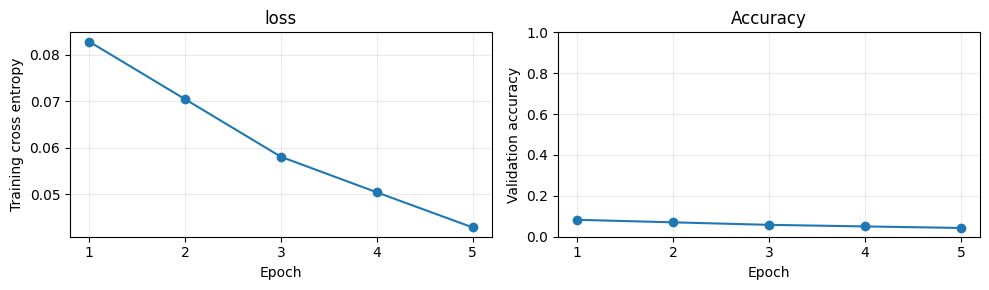

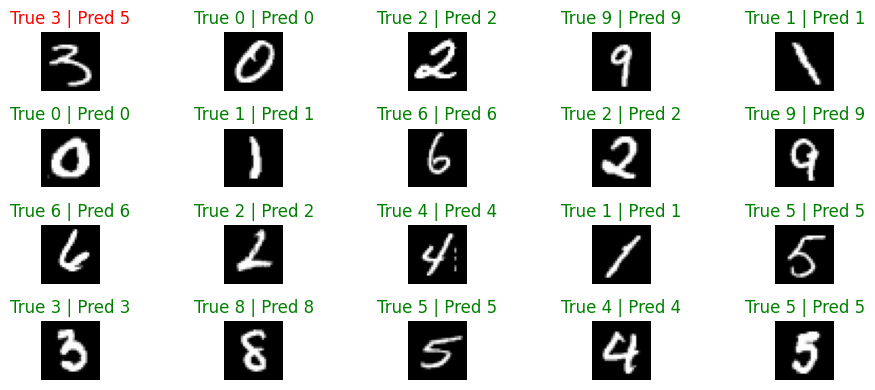

In [146]:
epochs = np.arange(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize = (10, 3))
axes[0].plot(epochs, [row[0] for row in history], marker = 'o')
axes[0].set(xlabel = "Epoch", ylabel = "Training cross entropy", title = "loss")
axes[1].plot(epochs, [row[0] for row in history], marker = 'o')
axes[1].set(xlabel = "Epoch", ylabel = "Validation accuracy", title = "Accuracy", ylim = [0, 1])

for ax in axes:
    ax.set_xticks(epochs)
    ax.grid(alpha = 0.25)

plt.tight_layout()
plt.show()

example_ids = np.random.choice(len(X_val), size=min(20, len(X_val)), replace=False)
predictions = predict_logits(model, X_val[example_ids]).argmax(axis = 1)
fig, axes = plt.subplots(4, 5, figsize = (10, 4))
for ax, image, actual, predicted in zip(axes.flat, X_val[example_ids], y_val[example_ids], predictions):
    ax.imshow(image.reshape(28, 28), cmap = 'gray', vmin = 0, vmax = 1)
    ax.set_title(f'True {actual} | Pred {predicted}', color = "green" if actual == predicted else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 8. Prediction after training

In [149]:
example_ids = np.random.choice(
    len(pixels_test), size=min(10, len(pixels_test)), replace=False
)

for i in range(len(example_ids)):
    x = example_ids[i]
    print("---------------")
    digit, probabilities = predict_digit(model, pixels_test[x].reshape(28, 28))
    print(f'image: {i+1}: predicted {digit}, true label {labels_test[x]}\n')
    print('Probabilities for digits 0-9:', np.round(probabilities, 3))

---------------
image: 1: predicted 2, true label 2

Probabilities for digits 0-9: [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
---------------
image: 2: predicted 8, true label 8

Probabilities for digits 0-9: [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
---------------
image: 3: predicted 1, true label 1

Probabilities for digits 0-9: [0.    0.999 0.    0.    0.    0.    0.    0.    0.001 0.   ]
---------------
image: 4: predicted 4, true label 4

Probabilities for digits 0-9: [0.089 0.    0.002 0.    0.864 0.    0.015 0.001 0.006 0.024]
---------------
image: 5: predicted 7, true label 7

Probabilities for digits 0-9: [0.    0.    0.    0.    0.    0.    0.    0.999 0.    0.   ]
---------------
image: 6: predicted 3, true label 3

Probabilities for digits 0-9: [0.    0.    0.    0.998 0.    0.    0.    0.    0.001 0.001]
---------------
image: 7: predicted 0, true label 0

Probabilities for digits 0-9: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
---------------
image: 8: predicted 3, true label 3

Probabilities for digi